<a href="https://colab.research.google.com/github/Nayem-Mursalin/Random-DS-AI-Projects/blob/main/Iris_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#IRIS Dataset

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

# Set style for plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 7)

### Data Preprocessing

In [ ]:
# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# Create DataFrame
df = pd.DataFrame(X, columns=feature_names)
df['species'] = y
df['species_name'] = df['species'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Dataset Shape: (150, 6)

First 5 rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [ ]:
# Check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
species_name         0
dtype: int64

Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                int64
species_name          object
dtype: object


In [ ]:
# Scale the features (excluding the species columns)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled features shape:", X_scaled.shape)
print("\nFirst 5 rows of scaled features:")
print(X_scaled[:5])

Scaled features shape: (150, 4)

First 5 rows of scaled features:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


### Exploratory Data Analysis

In [ ]:
# Basic statistics
print("Basic Statistics:")
df.describe()

Basic Statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


### Visualization

<Figure size 1200x800 with 0 Axes>

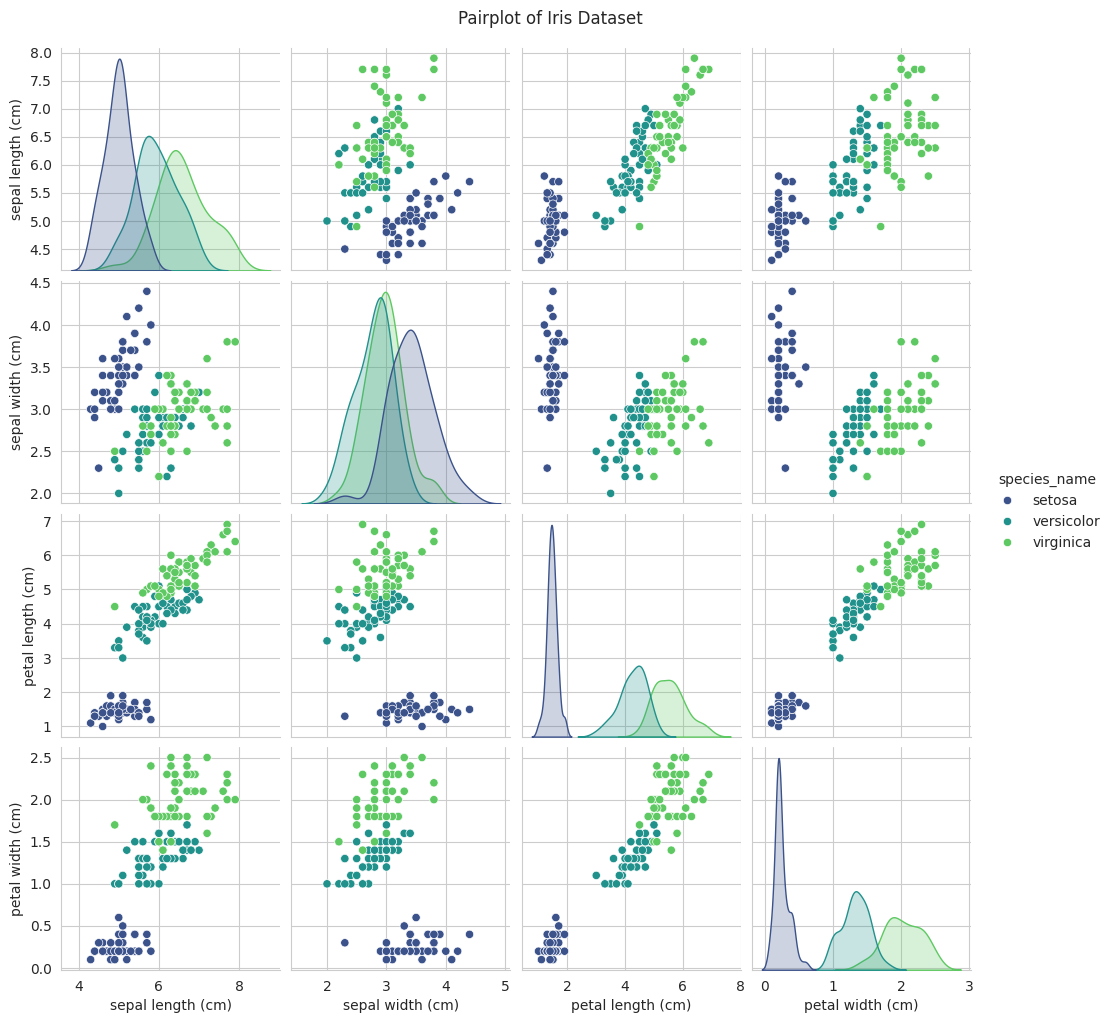

In [ ]:
# Pairplot to visualize relationships between features
plt.figure(figsize=(12, 8))
sns.pairplot(df.drop('species', axis=1), hue='species_name', palette='viridis')
plt.suptitle('Pairplot of Iris Dataset', y=1.02)
plt.show()

### Heatmap

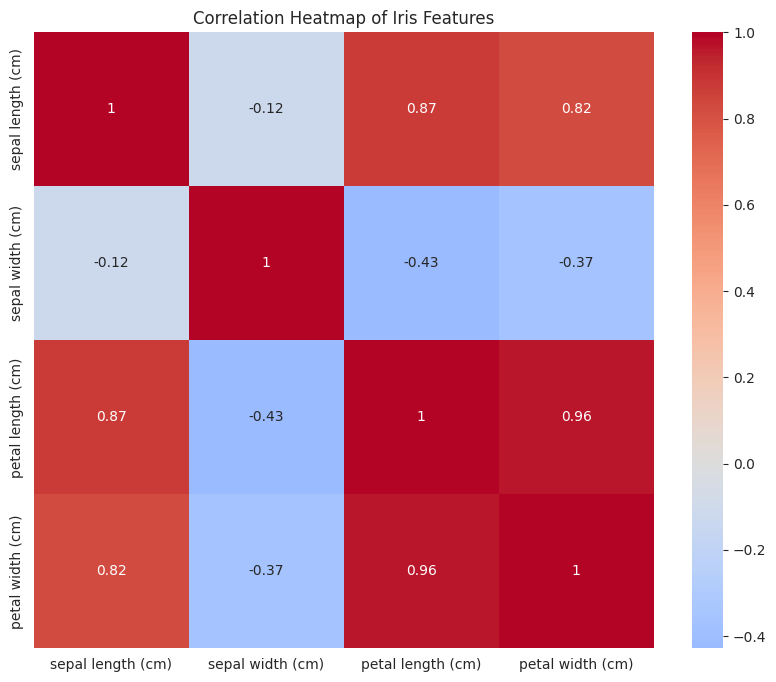

In [ ]:
# Correlation heatmap
plt.figure(figsize=(10, 8))
correlation_matrix = df.iloc[:, :4].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Iris Features')
plt.show()

### Applying Kmeans

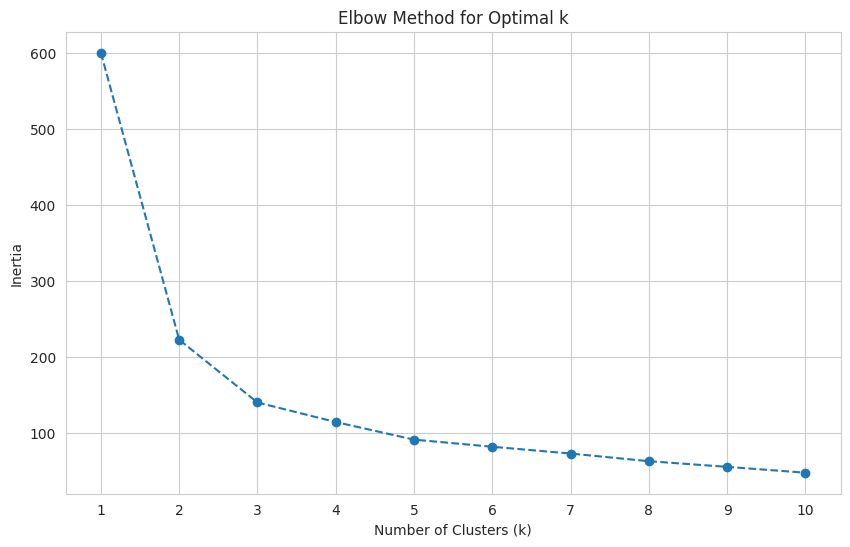

In [ ]:
# Elbow method to find optimal k
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot elbow curve
plt.figure(figsize=(10, 6))
plt.plot(k_range, inertia, marker='o', linestyle='--')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.xticks(k_range)
plt.show()

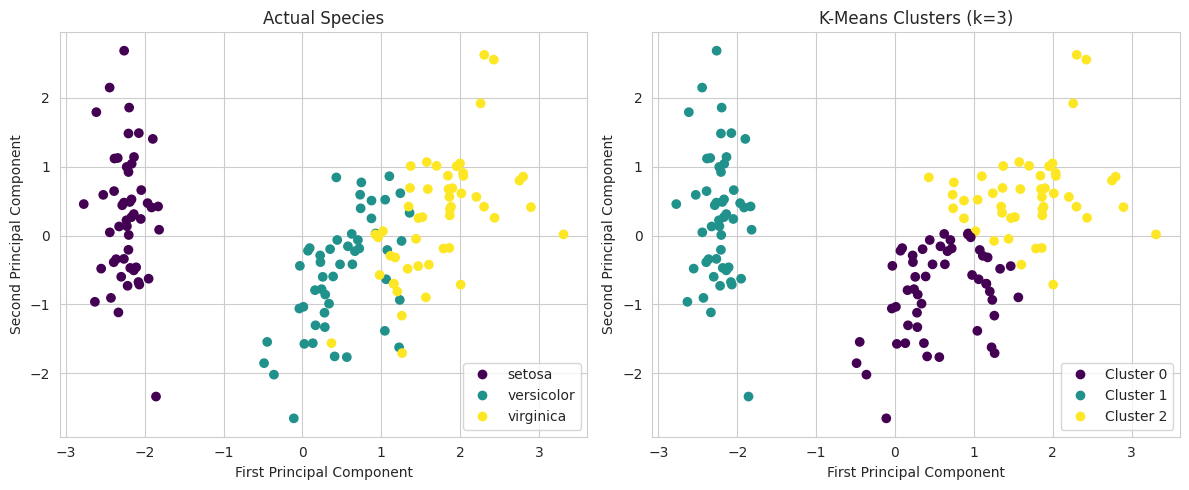

In [ ]:
# Apply K-Means with k=3 (based on elbow method and prior knowledge)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to dataframe
df['kmeans_cluster'] = kmeans_labels

# Visualize clusters using PCA for dimensionality reduction
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(12, 5))

# Plot actual species
plt.subplot(1, 2, 1)
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Actual Species')
plt.legend(handles=scatter.legend_elements()[0], labels=target_names.tolist())

# Plot K-Means clusters
plt.subplot(1, 2, 2)
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('K-Means Clusters (k=3)')
plt.legend(handles=scatter.legend_elements()[0], labels=['Cluster 0', 'Cluster 1', 'Cluster 2'])

plt.tight_layout()
plt.show()

### Hierarchical Clustering

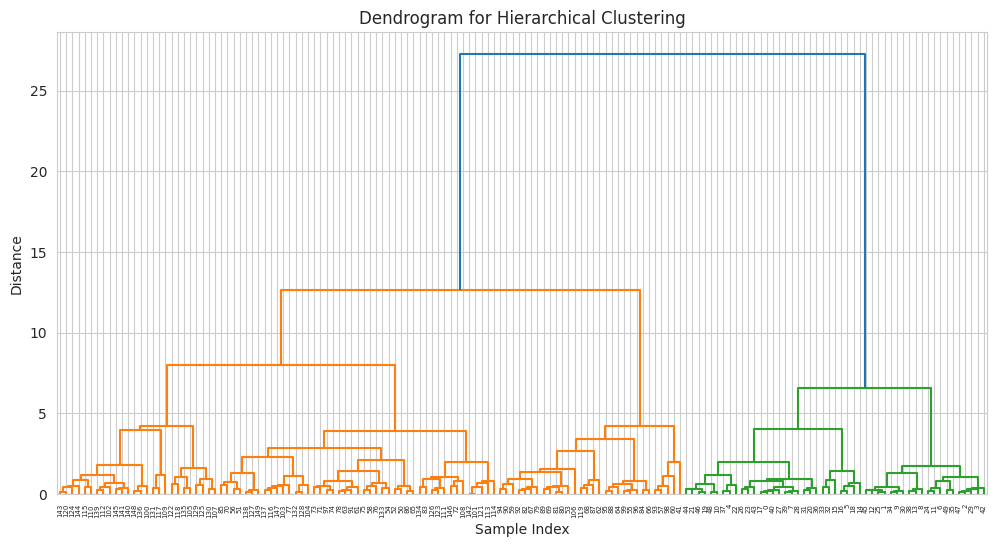

In [ ]:
# Plot dendrogram
plt.figure(figsize=(12, 6))
linked = linkage(X_scaled, method='ward')
dendrogram(linked, orientation='top', distance_sort='descending', show_leaf_counts=True)
plt.title('Dendrogram for Hierarchical Clustering')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

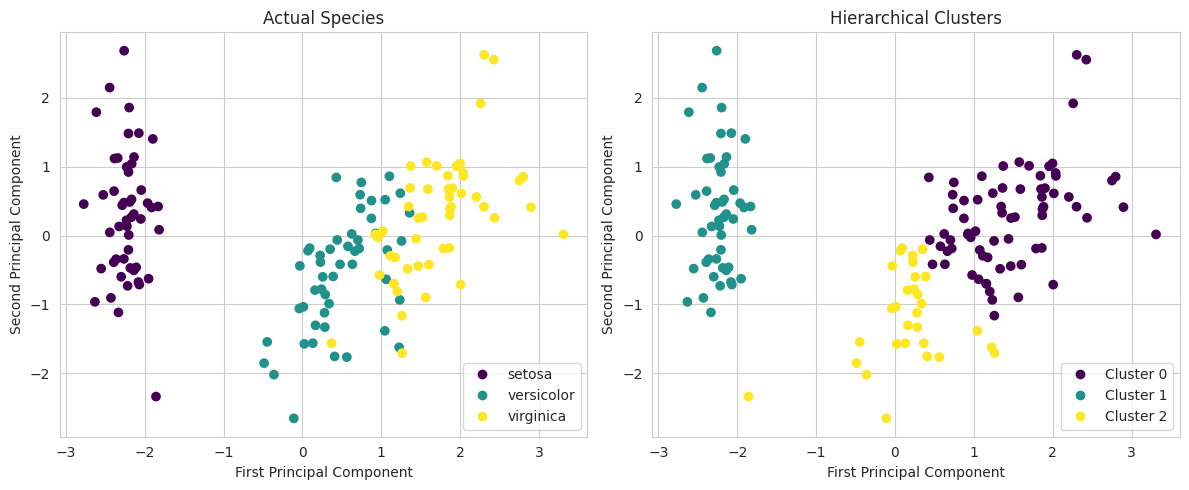

In [ ]:
# Apply Hierarchical Clustering with 3 clusters
hierarchical = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
hierarchical_labels = hierarchical.fit_predict(X_scaled)

# Add cluster labels to dataframe
df['hierarchical_cluster'] = hierarchical_labels

# Visualize hierarchical clusters
plt.figure(figsize=(12, 5))

# Plot actual species
plt.subplot(1, 2, 1)
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Actual Species')
plt.legend(handles=scatter.legend_elements()[0], labels=target_names.tolist())

# Plot hierarchical clusters
plt.subplot(1, 2, 2)
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=hierarchical_labels, cmap='viridis')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Hierarchical Clusters')
plt.legend(handles=scatter.legend_elements()[0], labels=['Cluster 0', 'Cluster 1', 'Cluster 2'])

plt.tight_layout()
plt.show()

### DBSCAN Clustering

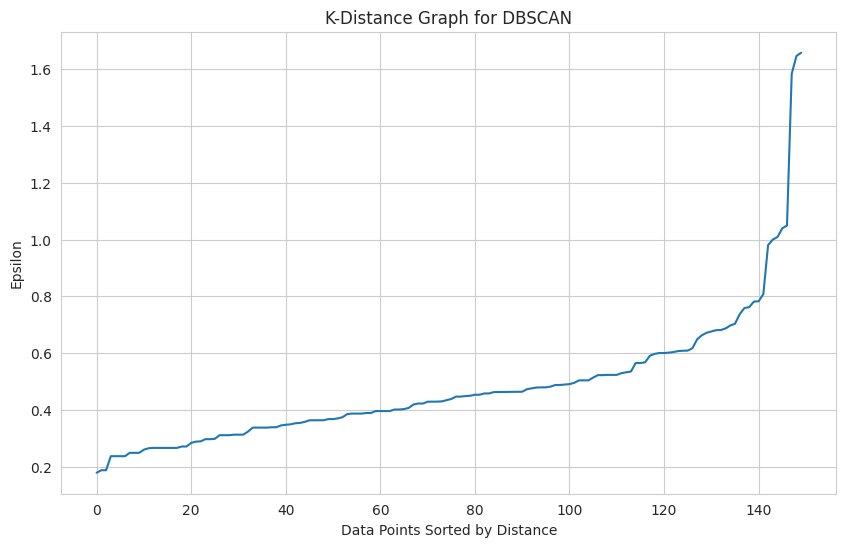

In [ ]:
# Find optimal eps using k-distance graph
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=4)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Sort distances
distances = np.sort(distances[:, 3], axis=0)

# Plot k-distance graph
plt.figure(figsize=(10, 6))
plt.plot(distances)
plt.xlabel('Data Points Sorted by Distance')
plt.ylabel('Epsilon')
plt.title('K-Distance Graph for DBSCAN')
plt.show()

DBSCAN found 2 clusters and 4 noise points.


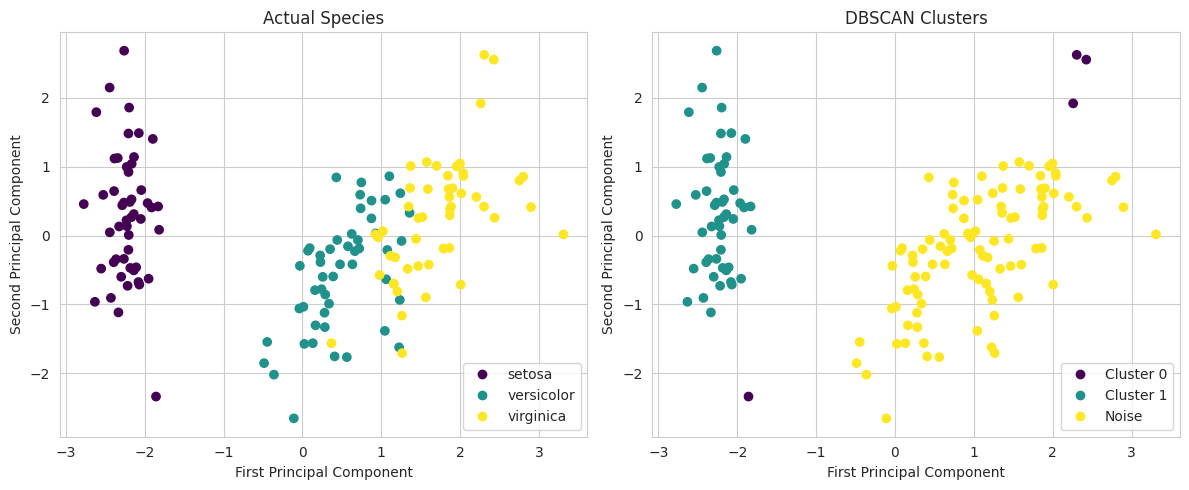

In [ ]:
# Apply DBSCAN with eps=0.8 and min_samples=4
dbscan = DBSCAN(eps=0.8, min_samples=4)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Count clusters and noise points
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print(f"DBSCAN found {n_clusters} clusters and {n_noise} noise points.")

# Add cluster labels to dataframe
df['dbscan_cluster'] = dbscan_labels

# Visualize DBSCAN clusters
plt.figure(figsize=(12, 5))

# Plot actual species
plt.subplot(1, 2, 1)
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Actual Species')
plt.legend(handles=scatter.legend_elements()[0], labels=target_names.tolist())

# Plot DBSCAN clusters
plt.subplot(1, 2, 2)
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='viridis')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('DBSCAN Clusters')
unique_labels = set(dbscan_labels)
legend_labels = [f'Noise' if label == -1 else f'Cluster {label}' for label in unique_labels]
plt.legend(handles=scatter.legend_elements()[0], labels=legend_labels)

plt.tight_layout()
plt.show()

### Evaluation
\

In [ ]:
# Compare cluster labels to actual species
print("K-Means Clustering Performance:")
print("Adjusted Rand Index:", adjusted_rand_score(y, kmeans_labels))

print("\nHierarchical Clustering Performance:")
print("Adjusted Rand Index:", adjusted_rand_score(y, hierarchical_labels))

print("\nDBSCAN Clustering Performance:")
print("Adjusted Rand Index:", adjusted_rand_score(y, dbscan_labels))

K-Means Clustering Performance:
Adjusted Rand Index: 0.6201351808870379

Hierarchical Clustering Performance:
Adjusted Rand Index: 0.6153229932145449

DBSCAN Clustering Performance:
Adjusted Rand Index: 0.5517553852833211


###

### Confusion Matrices

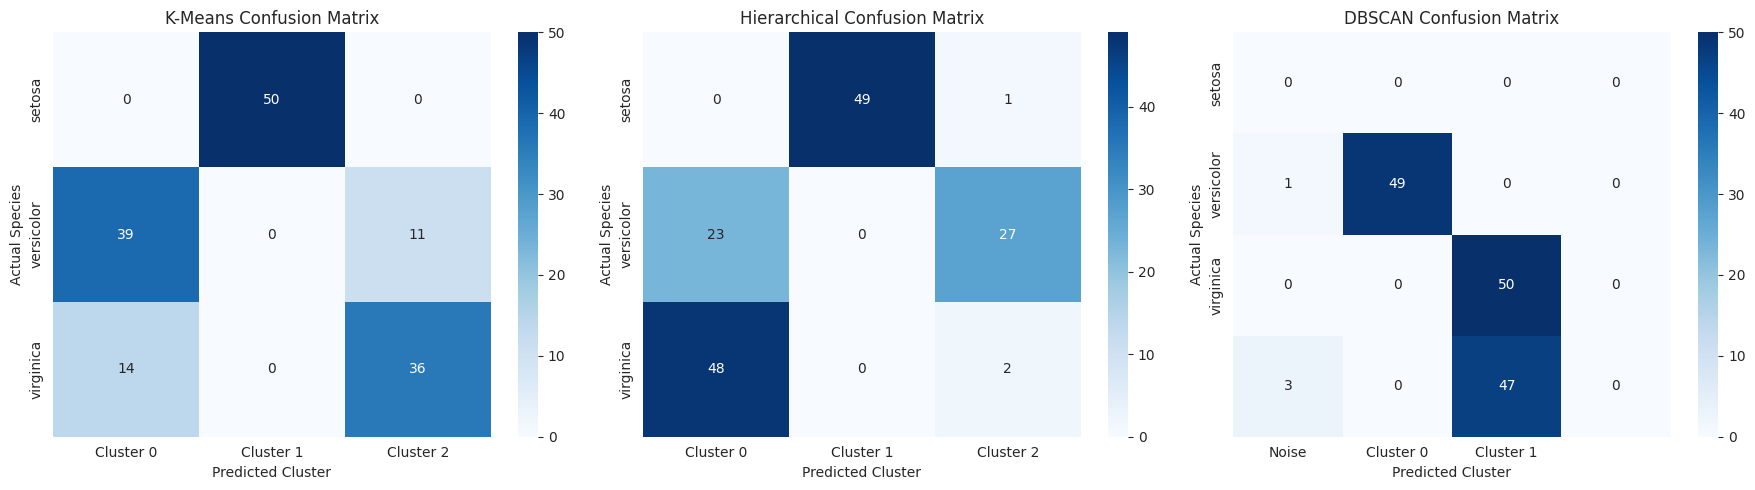

In [ ]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# K-Means confusion matrix
cm_kmeans = confusion_matrix(y, kmeans_labels)
sns.heatmap(cm_kmeans, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'],
            yticklabels=target_names)
axes[0].set_title('K-Means Confusion Matrix')
axes[0].set_xlabel('Predicted Cluster')
axes[0].set_ylabel('Actual Species')

# Hierarchical confusion matrix
cm_hierarchical = confusion_matrix(y, hierarchical_labels)
sns.heatmap(cm_hierarchical, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Cluster 0', 'Cluster 1', 'Cluster 2'],
            yticklabels=target_names)
axes[1].set_title('Hierarchical Confusion Matrix')
axes[1].set_xlabel('Predicted Cluster')
axes[1].set_ylabel('Actual Species')

# DBSCAN confusion matrix
dbscan_unique_labels = sorted(set(dbscan_labels))
cm_dbscan = confusion_matrix(y, dbscan_labels)
sns.heatmap(cm_dbscan, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=[f'Cluster {label}' if label != -1 else 'Noise' for label in dbscan_unique_labels],
            yticklabels=target_names)
axes[2].set_title('DBSCAN Confusion Matrix')
axes[2].set_xlabel('Predicted Cluster')
axes[2].set_ylabel('Actual Species')

plt.tight_layout()
plt.show()

In [ ]:
# Summary of results
results = pd.DataFrame({
    'Algorithm': ['K-Means', 'Hierarchical', 'DBSCAN'],
    'ARI Score': [
        adjusted_rand_score(y, kmeans_labels),
        adjusted_rand_score(y, hierarchical_labels),
        adjusted_rand_score(y, dbscan_labels)
    ],
    'Clusters Found': [
        len(set(kmeans_labels)),
        len(set(hierarchical_labels)),
        len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
    ],
    'Noise Points': [0, 0, n_noise]
})

print("Clustering Results Summary:")
results

Clustering Results Summary:


,Algorithm,ARI Score,Clusters Found,Noise Points
0,K-Means,0.620135,3,0
1,Hierarchical,0.615323,3,0
2,DBSCAN,0.551755,2,4
